# M2500T
Creates the RocketPy **`SolidMotor`** object `M2500T` (AeroTech M2500T, 98 mm). Every value comes from `25_26_MoS_Parameters`.

### How this notebook loads its inputs
This notebook doesn't redefine any numbers; it reads them from the notebooks it depends on.
- **Opened on its own:** the cell below runs its dependencies with IPython's `%run` (written as `get_ipython().run_line_magic("run", ...)` because the call sits inside an `if`). When `%run` runs a notebook it executes in the **same namespace**, so every variable it defines becomes available here.
- **Run from `Test_Flight_MoS`:** that notebook sets `PIPELINE = True` and has already loaded everything, so this cell skips the reload. `SHOW_INFO` turns off the `.info()` printouts and plots so the test flight output stays clean.

In [1]:
from rocketpy import Rocket, SolidMotor, Environment, Flight   # simulation classes
import numpy as np                                              # arrays and maths
import pandas as pd                                             # reading .xlsx data files
import datetime                                                 # launch date for the forecast
import matplotlib.pyplot as plt                                 # plotting

In [2]:
# PIPELINE is set to True by Test_Flight_MoS before it runs this notebook.
#   True  -> dependencies are already loaded; skip the info printouts and plots
#   False -> this notebook was opened on its own, so load what it needs first
PIPELINE = globals().get("PIPELINE", False)
if not PIPELINE:
    get_ipython().run_line_magic("run", "25_26_MoS_Parameters.ipynb")   # load 25_26_MoS_Parameters
SHOW_INFO = not PIPELINE   # only print .info() / draw plots when run on its own

## SolidMotor
RocketPy models a solid motor as a **thrust curve plus a burning grain stack**, so it can track how the propellant's mass, CG and inertia change during the burn. That shift moves the rocket's CG forward during the burn, which is why the stability margin rises from launch to burnout.
- **`thrust_source` / `burn_time`:** the thrust curve from the `.eng` file. `burn_time` cuts it off at the listed burn time.
- **`dry_mass` / `dry_inertia` / `center_of_dry_mass_position`:** the empty case, which stays with the rocket after burnout.
- **`grain_*`:** the grain geometry. RocketPy regresses the core radius over the burn so the burning rate follows the thrust curve.
- **`nozzle_radius` / `throat_radius`:** approximate nozzle dimensions.
- **`coordinate_system_orientation="nozzle_to_combustion_chamber"`:** positions *inside the motor* are measured from the nozzle exit (`nozzle_position=0`) toward the forward closure. This is separate from the rocket's own nose-to-tail coordinates. `Method_of_Sections` places this origin at `MOTOR_POSITION`.

**Check:** `M2500T.info()` prints total impulse and average thrust. Compare them with the manufacturer or ThrustCurve.org figures. Your last run gave 9,573 N·s total impulse and 2,245 N average thrust.

Nozzle Details
Nozzle Radius: 0.033 m
Nozzle Throat Radius: 0.016 m

Grain Details
Number of Grains: 4
Grain Spacing: 0.004 m
Grain Density: 1724.1045383769072 kg/m3
Grain Outer Radius: 0.04 m
Grain Inner Radius: 0.016 m
Grain Height: 0.16 m
Grain Volume: 0.001 m3
Grain Mass: 1.165 kg

Motor Details
Total Burning Time: 4.264 s
Total Propellant Mass: 4.659 kg
Structural Mass Ratio: 0.422
Average Propellant Exhaust Velocity: 2054.731 m/s
Average Thrust: 2245.074 N
Maximum Thrust: 2861.69 N at 1.252 s after ignition.
Total Impulse: 9572.994 Ns



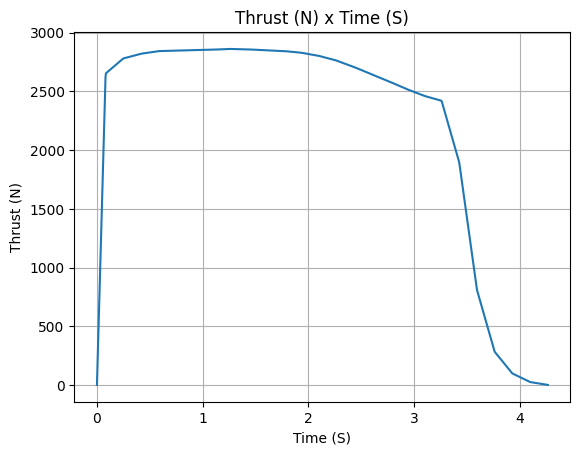

In [3]:
M2500T = SolidMotor(
    thrust_source=THRUST_CURVE,                         # (time, thrust) array from the .eng file
    burn_time=MOTOR_BURN_TIME,                          # s
    dry_mass=MOTOR_DRY_MASS,                            # kg empty case
    dry_inertia=(case_I_long, case_I_long, case_I_roll),# kg*m^2 (pitch, yaw, roll) of the empty case
    center_of_dry_mass_position=MOTOR_LENGTH / 2,       # m from nozzle, case CG at mid-length
    grains_center_of_mass_position=MOTOR_LENGTH / 2,    # m from nozzle, grain stack centred in case
    grain_number=N_GRAINS,
    grain_density=GRAIN_DENSITY,                        # kg/m^3 (sized to give the real propellant mass)
    grain_outer_radius=GRAIN_R_OUT,                     # m
    grain_initial_inner_radius=GRAIN_R_IN,              # m, core radius at ignition
    grain_initial_height=GRAIN_H,                       # m, length of each grain
    grain_separation=GRAIN_SEP,                         # m, gap between grains
    nozzle_radius=0.033,                                # m, nozzle exit (approximate)
    throat_radius=0.016,                                # m, nozzle throat (approximate)
    nozzle_position=0.0,                                # motor origin is the nozzle exit
    coordinate_system_orientation="nozzle_to_combustion_chamber",   # +x from nozzle toward forward closure
)

if SHOW_INFO:
    M2500T.info()               # impulse, average/max thrust, thrust curve plot